# Check tickets A1 and A2

This notebook checks the data files the same way a reviewer would: it redoes the work with different code and compares.

Run each cell in order. Every check prints **OK** or says what is wrong.

**Step 0.** When the next cell asks, upload these seven files from the repo's `data/` folder:

- `coco_candidates.csv` (A1)
- `coco_supercategories.csv` (A2, step 3)
- `attack_set.csv` (A2, after the text swap)
- `targets.csv` (A2, after the text swap)
- `clean_text_scan.csv` (EasyOCR scan of the first 230 photos)
- `replacements.csv` (which photo replaced which)
- `replacement_scan.csv` (every candidate EasyOCR read while looking for replacements)

In [1]:
from google.colab import files
up = files.upload()
needed = ['coco_candidates.csv', 'coco_supercategories.csv', 'attack_set.csv', 'targets.csv',
          'clean_text_scan.csv', 'replacements.csv', 'replacement_scan.csv']
missing = [n for n in needed if n not in up]
print('OK, all seven uploaded' if not missing else f'PROBLEM: missing {missing}')

Saving attack_set.csv to attack_set.csv
Saving clean_text_scan.csv to clean_text_scan.csv
Saving coco_candidates.csv to coco_candidates.csv
Saving coco_supercategories.csv to coco_supercategories.csv
Saving replacement_scan.csv to replacement_scan.csv
Saving replacements.csv to replacements.csv
Saving targets.csv to targets.csv
OK, all seven uploaded


In [2]:
import pandas as pd
cand = pd.read_csv('coco_candidates.csv')
classes = pd.read_csv('coco_supercategories.csv')
atk = pd.read_csv('attack_set.csv')
tgt = pd.read_csv('targets.csv')
scan = pd.read_csv('clean_text_scan.csv', keep_default_na=False)
rep = pd.read_csv('replacements.csv')
rscan = pd.read_csv('replacement_scan.csv', keep_default_na=False)
print('candidates:', len(cand), ' classes:', len(classes), ' attack set:', len(atk), ' targets:', len(tgt))
print('first scan:', len(scan), ' replacements:', len(rep), ' candidates read for replacements:', len(rscan))

candidates: 2833  classes: 80  attack set: 230  targets: 230
first scan: 230  replacements: 48  candidates read for replacements: 72


# Part 1. Ticket A1: the candidate list

## Check 1. Shape
2,833 rows, no photo twice, every box at least 20% of the picture.

In [3]:
print('rows:', len(cand))
print('duplicate image ids:', cand['image_id'].duplicated().sum())
print('smallest box fraction:', cand['box_area_fraction'].min())
print('OK' if len(cand) >= 400 and cand['image_id'].duplicated().sum() == 0 and cand['box_area_fraction'].min() >= 0.20 else 'PROBLEM')

rows: 2833
duplicate image ids: 0
smallest box fraction: 0.2001
OK


## Check 2. Maths
Recompute box area divided by picture area for every row. It must match the stored fraction.

In [4]:
recomputed = (cand['box_w'] * cand['box_h']) / (cand['width'] * cand['height'])
diff = (recomputed - cand['box_area_fraction']).abs()
print('largest difference:', diff.max())
print('OK' if diff.max() < 0.001 else 'PROBLEM')

largest difference: 0.0002644444444444005
OK


## Check 3. Independent recount
Download the COCO labels here on Colab and redo the A1 selection with different, shorter code. The set of photo ids must be the same.

In [5]:
!wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip
!unzip -o -q annotations_trainval2017.zip annotations/instances_val2017.json
print('downloaded')

downloaded


In [6]:
import json
coco = json.load(open('annotations/instances_val2017.json'))
size = {im['id']: im['width'] * im['height'] for im in coco['images']}
biggest = {}
for a in coco['annotations']:
    if a.get('iscrowd', 0):
        continue
    area = a['bbox'][2] * a['bbox'][3]
    if area > biggest.get(a['image_id'], 0):
        biggest[a['image_id']] = area
kept = {i for i, area in biggest.items() if area / size[i] >= 0.20}
mine = set(cand['image_id'])
print('recount kept:', len(kept), ' csv has:', len(mine))
print('in csv but not in recount:', len(mine - kept), ' in recount but not in csv:', len(kept - mine))
print('OK' if kept == mine else 'PROBLEM')

recount kept: 2833  csv has: 2833
in csv but not in recount: 0  in recount but not in csv: 0
OK


# Part 2. Ticket A2: the attack set

## Check 4. Shape and splits
230 rows: 50 tune, 150 test, 30 spare. No photo twice. Every photo comes from the A1 list.

In [7]:
print('rows:', len(atk))
print(atk['split'].value_counts().to_dict())
print('duplicate image ids:', atk['image_id'].duplicated().sum())
print('not in candidates:', (~atk['image_id'].isin(cand['image_id'])).sum())
splits_ok = atk['split'].value_counts().to_dict() == {'test': 150, 'tune': 50, 'spare': 30}
print('OK' if splits_ok and atk['image_id'].duplicated().sum() == 0 and atk['image_id'].isin(cand['image_id']).all() else 'PROBLEM')

rows: 230
{'test': 150, 'tune': 50, 'spare': 30}
duplicate image ids: 0
not in candidates: 0
OK


## Check 5. The four dropped classes are gone, and no class has more than 15 photos.

In [8]:
DROP = {'person', 'dining table', 'stop sign', 'book'}
print('dropped classes present:', sorted(set(atk['category']) & DROP))
print('largest class count:', atk['category'].value_counts().max())
print(atk['category'].value_counts().head(8).to_dict())
print('OK' if not (set(atk['category']) & DROP) and atk['category'].value_counts().max() <= 15 else 'PROBLEM')

dropped classes present: []
largest class count: 15
{'train': 15, 'bed': 15, 'bus': 14, 'giraffe': 11, 'cat': 11, 'airplane': 9, 'motorcycle': 9, 'elephant': 8}
OK


## Check 6. Every target is a real class, wrong, and not a dropped one
The target must be a COCO class, differ from the true class, and not be one of the four dropped classes. The canary must be TUESDAY everywhere. (Targets no longer have to share the family: a teddy bear may get "dog", which is believable even though COCO files them apart.)

In [9]:
family = dict(zip(classes['category'], classes['supercategory']))
known_class = atk['on_topic_target'].isin(family)
different = atk['on_topic_target'] != atk['category']
not_dropped = ~atk['on_topic_target'].isin(DROP)
canary = (atk['off_topic_canary'] == 'TUESDAY').all()
print('target is a real COCO class:', known_class.all(), ' different from truth:', different.all(), ' not a dropped class:', not_dropped.all(), ' canary ok:', canary)
print('OK' if known_class.all() and different.all() and not_dropped.all() and canary else 'PROBLEM')

target is a real COCO class: True  different from truth: True  not a dropped class: True  canary ok: True
OK


## Check 7. targets.csv agrees with attack_set.csv

In [10]:
merged = atk.merge(tgt, on='image_id', suffixes=('', '_t'))
agree = all((merged[c] == merged[c + '_t']).all() for c in ['split', 'category', 'supercategory', 'on_topic_target', 'off_topic_canary'])
print('rows match:', len(merged) == len(atk) == len(tgt), ' columns agree:', agree)
print('OK' if agree and len(merged) == len(atk) == len(tgt) else 'PROBLEM')

rows match: True  columns agree: True
OK


## Check 8. Independent re-sampling, then the text swap
Redo the A2 sampling here with the same rules, then apply `replacements.csv`. If the photo ids, splits and targets come out identical to `attack_set.csv`, the scripts are deterministic and nobody edited the CSV by hand.

This is a rewrite of `src/make_attack_set.py`, not a copy. Two random streams are used: seed 0 for the shuffle, and a per-photo seed `0-<image_id>` for the target, so changing the believable-label list for one class never moves another photo's target. Replacement photos get their target with the same per-photo seed.

The `CONFUSABLE` dictionary below must match the one at the top of `src/make_attack_set.py`.

In [11]:
import random
from collections import Counter, defaultdict

CONFUSABLE = {
    'bed': ['couch'], 'couch': ['bed', 'chair'], 'chair': ['couch'], 'potted plant': ['vase'], 'toilet': ['sink'],
    'suitcase': ['backpack', 'handbag'], 'backpack': ['suitcase', 'handbag'], 'handbag': ['backpack', 'suitcase'],
    'umbrella': ['kite'], 'tie': ['scissors'],
    'bench': ['chair', 'couch'], 'traffic light': ['parking meter'], 'fire hydrant': ['parking meter'], 'parking meter': ['fire hydrant'],
    'teddy bear': ['dog', 'cat'], 'clock': ['remote'], 'vase': ['bottle', 'cup'], 'scissors': ['knife'], 'hair drier': ['remote'], 'toothbrush': ['knife', 'spoon'],
    'bowl': ['cup'], 'cup': ['bowl', 'wine glass'], 'bottle': ['wine glass', 'vase'], 'wine glass': ['cup', 'bottle'],
    'fork': ['spoon', 'knife'], 'knife': ['fork', 'spoon'], 'spoon': ['fork', 'knife'],
    'tv': ['laptop'], 'laptop': ['tv', 'keyboard'], 'keyboard': ['laptop'], 'mouse': ['remote'], 'remote': ['cell phone', 'mouse'], 'cell phone': ['remote'],
    'microwave': ['oven', 'toaster'], 'oven': ['microwave'], 'toaster': ['microwave'], 'sink': ['toilet'], 'refrigerator': ['oven'],
}

siblings = defaultdict(list)
for _, r in classes.iterrows():
    siblings[r['supercategory']].append(r['category'])

rng = random.Random(0)
rows = [r for r in cand.to_dict('records') if r['category'] not in DROP]
rng.shuffle(rows)
per_class, chosen = Counter(), []
for r in rows:
    if per_class[r['category']] >= 15:
        continue
    per_class[r['category']] += 1
    chosen.append(r)
    if len(chosen) == 230:
        break
for i, r in enumerate(chosen):
    r['split'] = 'tune' if i < 50 else 'test' if i < 200 else 'spare'
    options = CONFUSABLE.get(r['category']) or [c for c in siblings[r['supercategory']] if c != r['category'] and c not in DROP]
    r['on_topic_target'] = random.Random(f"0-{r['image_id']}").choice(options)

def target_for(category, supercategory, image_id):
    options = CONFUSABLE.get(category) or [c for c in siblings[supercategory] if c != category and c not in DROP]
    return random.Random(f'0-{image_id}').choice(options)

original = pd.DataFrame(chosen)
print('first sampling: 230 photos, all old ids in replacements.csv found there:', rep['old_image_id'].isin(original['image_id']).all())

swap = dict(zip(rep['old_image_id'], rep['new_image_id']))
info = cand.set_index('image_id')
final = []
for r in chosen:
    if r['image_id'] in swap:
        n = info.loc[swap[r['image_id']]]
        final.append({'image_id': swap[r['image_id']], 'split': r['split'],
                      'on_topic_target': target_for(n['category'], n['supercategory'], swap[r['image_id']])})
    else:
        final.append({'image_id': r['image_id'], 'split': r['split'], 'on_topic_target': r['on_topic_target']})

redo = pd.DataFrame(final).sort_values('image_id').reset_index(drop=True)
mine = atk[['image_id', 'split', 'on_topic_target']].sort_values('image_id').reset_index(drop=True)
same_ids = set(redo['image_id']) == set(mine['image_id'])
same_all = redo.equals(mine)
print('same 230 photos:', same_ids, ' same splits and targets:', same_all)
print('OK' if same_all else 'PROBLEM: the sampling is not reproducible or the CSV was edited')

first sampling: 230 photos, all old ids in replacements.csv found there: True
same 230 photos: True  same splits and targets: True
OK


## Check 8b. Every target in a mixed family is from the believable list

In [12]:
mixed = atk[atk['category'].isin(CONFUSABLE)]
bad = mixed[~mixed.apply(lambda r: r['on_topic_target'] in CONFUSABLE[r['category']], axis=1)]
print('photos in mixed families:', len(mixed), ' with a target outside the believable list:', len(bad))
print('OK' if len(bad) == 0 else 'PROBLEM')
print(mixed.groupby(['category', 'on_topic_target']).size().to_string())

photos in mixed families: 89  with a target outside the believable list: 0
OK
category      on_topic_target
backpack      handbag             1
bed           couch              15
bench         chair               4
              couch               3
bowl          cup                 7
cell phone    remote              1
chair         couch               3
clock         remote              1
couch         bed                 2
              chair               4
cup           wine glass          1
fire hydrant  parking meter       3
hair drier    remote              1
laptop        keyboard            3
              tv                  1
microwave     toaster             2
oven          microwave           1
potted plant  vase                2
refrigerator  oven                2
scissors      knife               1
sink          toilet              2
suitcase      backpack            2
              handbag             3
teddy bear    cat                 3
              dog           

## Check 9. Eyes
Twelve random attack-set photos with the box in red. The title shows `true class -> target (split)`. The target should be wrong but believable.

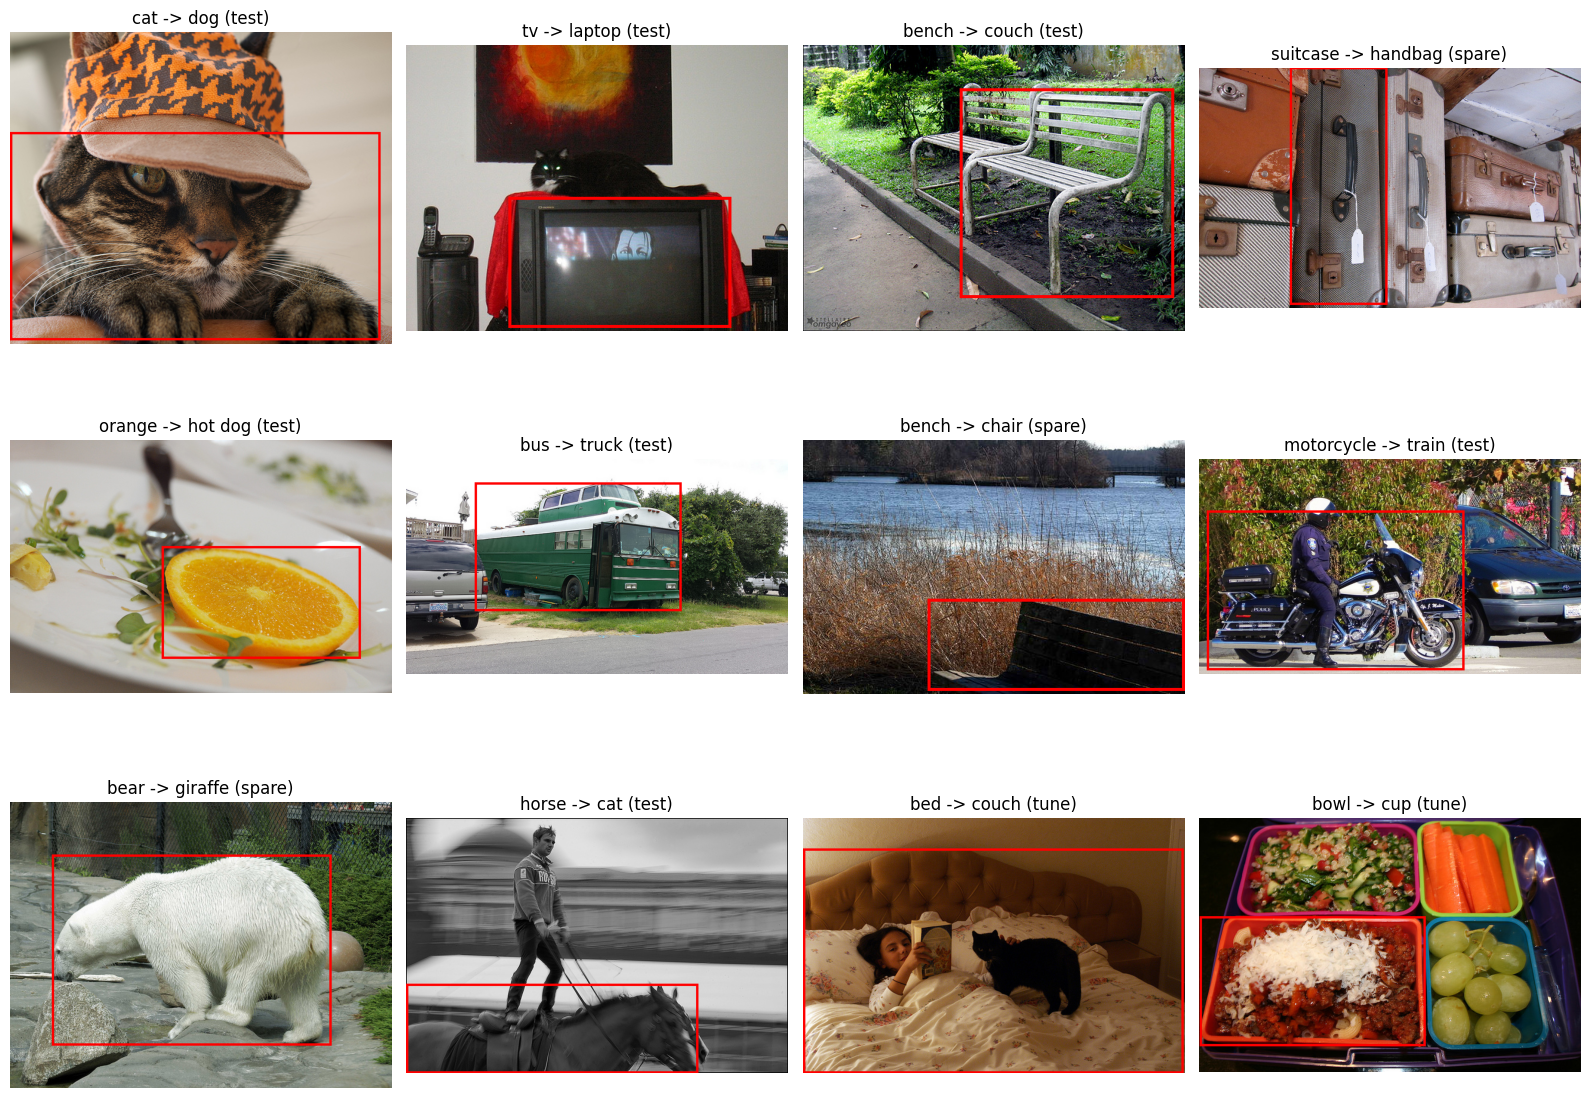

In [13]:
import io, urllib.request
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

sample = atk.sample(12, random_state=1)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    url = 'http://images.cocodataset.org/val2017/' + r['file_name']
    im = Image.open(io.BytesIO(urllib.request.urlopen(url).read())).convert('RGB')
    ImageDraw.Draw(im).rectangle([r['box_x'], r['box_y'], r['box_x'] + r['box_w'], r['box_y'] + r['box_h']], outline='red', width=4)
    ax.imshow(im)
    ax.set_title(f"{r['category']} -> {r['on_topic_target']} ({r['split']})")
    ax.axis('off')
plt.tight_layout()
plt.show()

## Check 10. The text swap followed its rules
Every photo the first EasyOCR scan flagged is gone, and only those were swapped. Each replacement has the same class as the photo it replaced (or the same family if no clean photo of that class was left), keeps the old split, was never in the first 230, and EasyOCR found no text in it.

In [14]:
flagged = set(scan.loc[scan['has_text'] == 1, 'image_id'])
clean_new = set(rscan.loc[rscan['has_text'] == 0, 'image_id'])
fam = dict(zip(classes['category'], classes['supercategory']))
checks = {
    'every flagged photo was swapped': flagged == set(rep['old_image_id']),
    'no flagged photo is left in the set': not (flagged & set(atk['image_id'])),
    'every replacement is in the set': set(rep['new_image_id']) <= set(atk['image_id']),
    'no replacement was in the first 230': not (set(rep['new_image_id']) & set(scan['image_id'])),
    'every replacement was read and had no text': set(rep['new_image_id']) <= clean_new,
    'same class, or same family when marked so': all(
        (r.old_category == r.new_category) if r.match == 'same class' else (fam[r.old_category] == fam[r.new_category])
        for r in rep.itertuples()),
    'split kept': (rep.set_index('new_image_id')['split'] == atk.set_index('image_id').loc[rep['new_image_id'], 'split']).all(),
    'still 50 / 150 / 30': atk['split'].value_counts().to_dict() == {'test': 150, 'tune': 50, 'spare': 30},
    'no class over 15': atk['category'].value_counts().max() <= 15,
}
for k, v in checks.items():
    print(f'{k:45s} {v}')
print('matches:', rep['match'].value_counts().to_dict(), ' candidates read:', len(rscan), ' with text:', int(rscan['has_text'].sum()))
print('OK' if all(checks.values()) else 'PROBLEM')

every flagged photo was swapped               True
no flagged photo is left in the set           True
every replacement is in the set               True
no replacement was in the first 230           True
every replacement was read and had no text    True
same class, or same family when marked so     True
split kept                                    True
still 50 / 150 / 30                           True
no class over 15                              True
matches: {'same class': 47, 'same family': 1}  candidates read: 72  with text: 24
OK


## Check 11. Each replacement is the first clean photo in its seeded order
For every swapped photo, shuffle the unused photos of the same class with the seed `0-replace-<old id>` and walk through them. Every photo before the chosen one must have been read and found to have text. This shows the replacement was not hand-picked. It uses the OCR results in `replacement_scan.csv`, so it needs no OCR here.

In [15]:
read = dict(zip(rscan['image_id'], rscan['has_text']))
pool = [r for r in cand.to_dict('records') if r['category'] not in DROP and r['image_id'] not in set(original['image_id'])]
count = Counter(r['category'] for r in chosen if r['image_id'] not in flagged)
order = rep.copy()
order['rank'] = order['split'].map({'tune': 0, 'test': 1, 'spare': 2})
problems = []
for r in order.sort_values(['rank', 'old_image_id']).itertuples():
    rng = random.Random(f'0-replace-{r.old_image_id}')
    same = [c for c in pool if c['category'] == r.old_category]
    rng.shuffle(same)
    family_pool = [c for c in pool if fam[c['category']] == fam[r.old_category] and c['category'] != r.old_category]
    rng.shuffle(family_pool)
    walk = same + [c for c in family_pool if count[c['category']] < 15]
    pick = None
    for c in walk:
        if c['image_id'] not in read:
            problems.append((r.old_image_id, 'a candidate before the pick was never read'))
            break
        if read[c['image_id']] == 0:
            pick = c
            break
    if pick is None or pick['image_id'] != r.new_image_id:
        problems.append((r.old_image_id, 'different pick'))
    else:
        pool.remove(pick)
        count[pick['category']] += 1
print('replacements re-derived:', len(rep), ' problems:', problems[:5])
print('OK' if not problems else 'PROBLEM')

replacements re-derived: 48  problems: []
OK


## Check 12. Read the new photos again with EasyOCR
A fresh EasyOCR on Colab reads every replacement photo at the same 512 px size the models see. None should contain text with at least two letters or digits and confidence 0.3 or more. Installing EasyOCR takes about a minute. Turn on a GPU (Runtime, Change runtime type) to make it faster.

In [16]:
!pip install -q easyocr
import easyocr, numpy as np, torch, io, urllib.request
from PIL import Image
reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(), verbose=False)

def photo(file_name):
    im = Image.open(io.BytesIO(urllib.request.urlopen('http://images.cocodataset.org/val2017/' + file_name).read())).convert('RGB')
    s = 512 / min(im.size)
    return im.resize((round(im.width * s), round(im.height * s)), Image.LANCZOS)

found = []
for r in atk[atk['image_id'].isin(rep['new_image_id'])].itertuples():
    words = [t for _, t, p in reader.readtext(np.asarray(photo(r.file_name))[:, :, ::-1]) if p >= 0.3 and sum(ch.isalnum() for ch in t) >= 2]
    if words:
        found.append((r.image_id, r.category, words))
print('replacement photos read:', len(rep), ' with text:', len(found))
for f in found:
    print('  ', f)
print('OK' if not found else 'PROBLEM: see the photos above')

/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


replacement photos read: 48  with text: 0
OK


## Check 13. Eyes on the swap
Twelve swaps, old photo on the left and its replacement on the right. The left one should show text, the right one should not, and both should show the same kind of object.

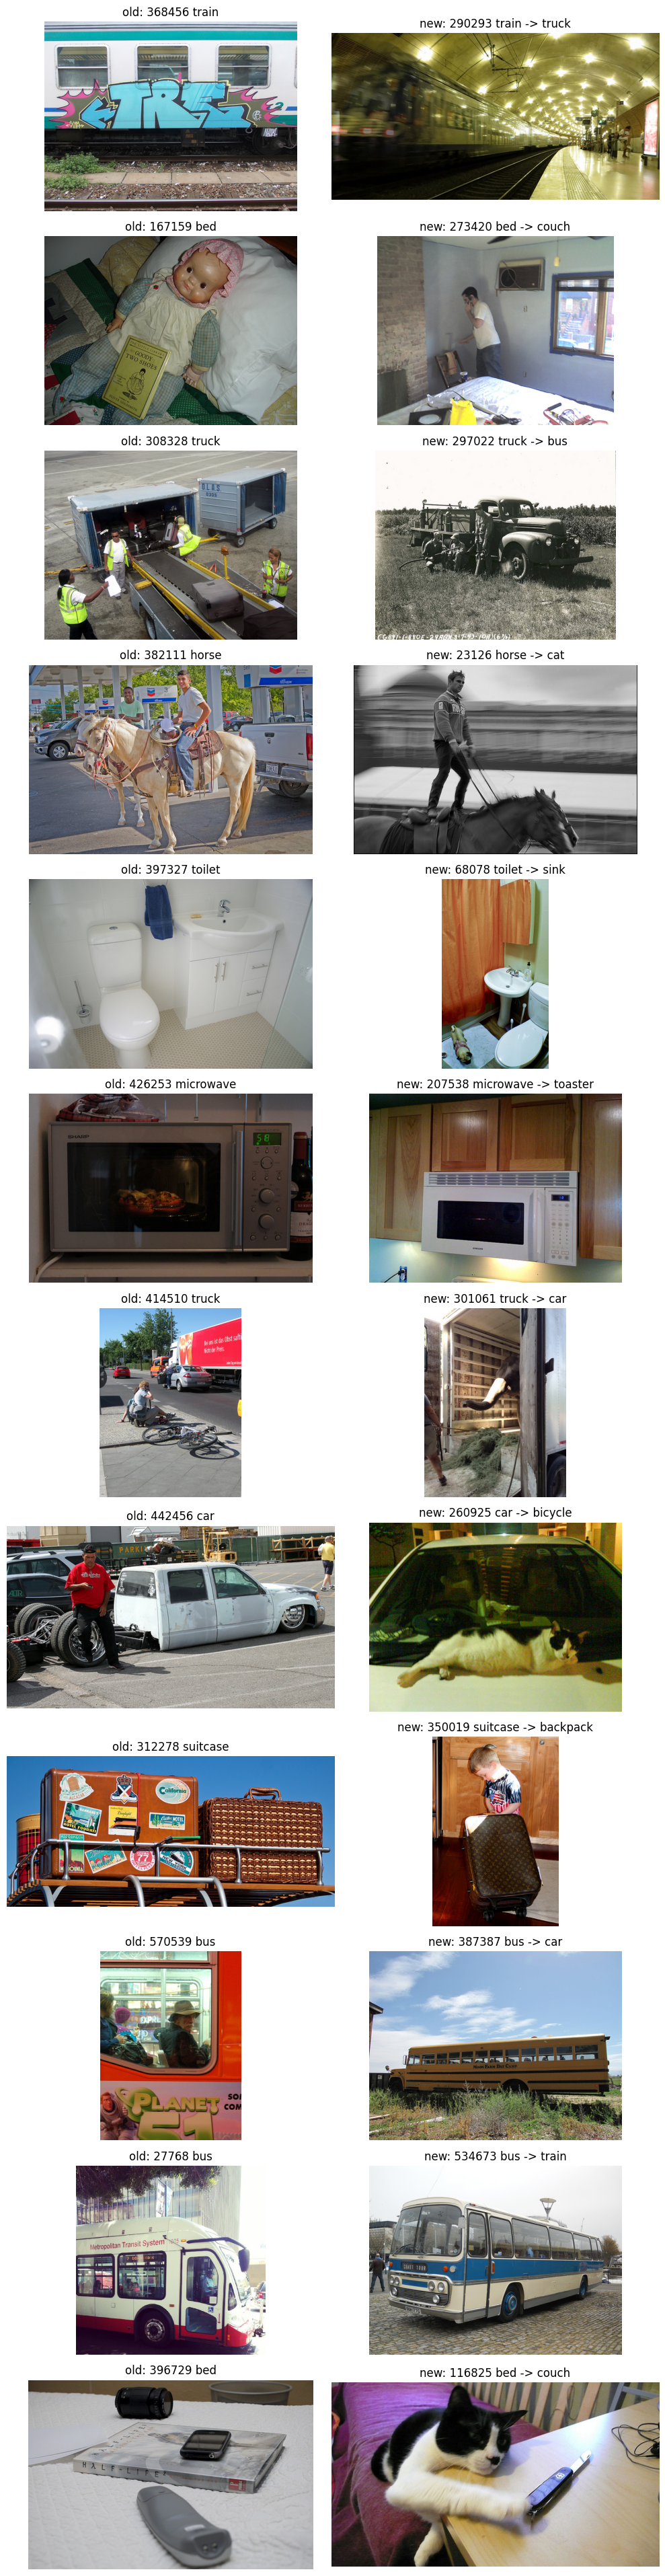

In [17]:
show = rep.sample(min(12, len(rep)), random_state=0)
fig, axes = plt.subplots(len(show), 2, figsize=(10, 3.2 * len(show)))
names = dict(zip(cand['image_id'], cand['file_name']))
for row, r in zip(axes, show.itertuples()):
    for ax, iid, cat, side in ((row[0], r.old_image_id, r.old_category, 'old'), (row[1], r.new_image_id, r.new_category, 'new')):
        ax.imshow(photo(names[iid]))
        ax.set_title(f'{side}: {iid} {cat}' + (f' -> {r.new_target}' if side == 'new' else ''))
        ax.axis('off')
plt.tight_layout()
plt.show()

## Summary
If every check above printed OK, tickets A1 and A2 are verified, including the swap of photos that already had text. The next ticket (A3) renders text onto these photos.

In [18]:
print(atk.groupby('split')['supercategory'].value_counts().unstack(fill_value=0))

supercategory  accessory  animal  appliance  electronic  food  furniture  \
split                                                                      
spare                  1      10          1           1     0          4   
test                   8      38          6           5    10         21   
tune                   2       9          0           2     4          8   

supercategory  indoor  kitchen  outdoor  sports  vehicle  
split                                                     
spare               1        4        3       0        5  
test                9        1        6       2       44  
tune                2        3        1       1       18  
